# Programas

## Problema 1: Decaimiento sin fuente. Factor de amplificación $R(z)$

$N' = -\lambda N$, $N(0) = N_0 = 100$, $\lambda = \tfrac12$.  Con $z = -\lambda h$:

| Esquema | $R(z)$ |
|---|---|
| Euler explícito (FE) | $1 + z$ |
| Euler implícito (BE) | $\dfrac{1}{1 - z}$ |
| Crank–Nicolson (CN) | $\dfrac{2 + z}{2 - z}$ |

Este notebook tabula $R$ al aumentar $\lambda h$ y grafica cómo se comporta cada esquema.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from fractions import Fraction

from pathlib import Path

FIG = Path.cwd().parent / "latex" / "figuras"
FIG.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})


lam, N0 = 0.5, 100.0

def R_FE(z): return 1 + z
def R_BE(z): return 1 / (1 - z)
def R_CN(z): return (2 + z) / (2 - z)

esquemas = {"Euler explícito": R_FE, "Euler implícito": R_BE, "Crank–Nicolson": R_CN}

## 1. Comprobación con los datos del problema ($h = \tfrac12$)

In [2]:
h = 0.5
z = -lam * h
Nex = N0 * np.exp(-lam * h)
print(f"lambda*h = {lam*h},  z = {z}")
print(f"N1 exacto = {Nex:.6f}\n")
for nombre, R in esquemas.items():
    N1 = R(z) * N0
    print(f"{nombre:16s}  R = {R(z):.6f}   N1 = {N1:.6f}   |error| = {abs(N1 - Nex):.6f}")

lambda*h = 0.25,  z = -0.25
N1 exacto = 77.880078

Euler explícito   R = 0.750000   N1 = 75.000000   |error| = 2.880078
Euler implícito   R = 0.800000   N1 = 80.000000   |error| = 2.119922
Crank–Nicolson    R = 0.777778   N1 = 77.777778   |error| = 0.102301


## 2. Tabla de $R$ para $\lambda h$ consecutivos

Como $\lambda = \tfrac12$, el paso es $h = 2\lambda h$. El primer renglón es el del problema.

In [3]:

lh = [Fraction(1, 4), 1, 2, 3, 4, 5, 10]

def frac(f):
    f = Fraction(f)
    return str(f.numerator) if f.denominator == 1 else f"{f.numerator}/{f.denominator}"

filas = []
for x in lh:
    x = Fraction(x)
    zz = -x
    filas.append({
        "λh": frac(x),
        "h": frac(x / Fraction(1, 2)),
        "R_FE": frac(1 + zz),
        "R_BE": frac(1 / (1 - zz)),
        "R_CN": frac((2 + zz) / (2 - zz)),
        "R_FE (dec)": float(1 + zz),
        "R_BE (dec)": float(1 / (1 - zz)),
        "R_CN (dec)": float((2 + zz) / (2 - zz)),
        "e^{-λh}": float(np.exp(-float(x))),
    })
tabla = pd.DataFrame(filas)
tabla.style.format({c: "{:.6f}" for c in ["R_FE (dec)", "R_BE (dec)", "R_CN (dec)"]} | {"e^{-λh}": "{:.6g}"}).hide(axis="index")

λh,h,R_FE,R_BE,R_CN,R_FE (dec),R_BE (dec),R_CN (dec),e^{-λh}
1/4,1/2,3/4,4/5,7/9,0.750000,0.800000,0.777778,0.778801
1,2,0,1/2,1/3,0.000000,0.500000,0.333333,0.367879
2,4,-1,1/3,0,-1.000000,0.333333,0.000000,0.135335
3,6,-2,1/4,-1/5,-2.000000,0.250000,-0.200000,0.0497871
4,8,-3,1/5,-1/3,-3.000000,0.200000,-0.333333,0.0183156
5,10,-4,1/6,-3/7,-4.000000,0.166667,-0.428571,0.00673795
10,20,-9,1/11,-2/3,-9.000000,0.090909,-0.666667,4.53999e-05


## 3. $R(z)$ contra $\lambda h$

Las líneas punteadas $R = \pm 1$ marcan el borde de la región de estabilidad ($|R| \le 1$).

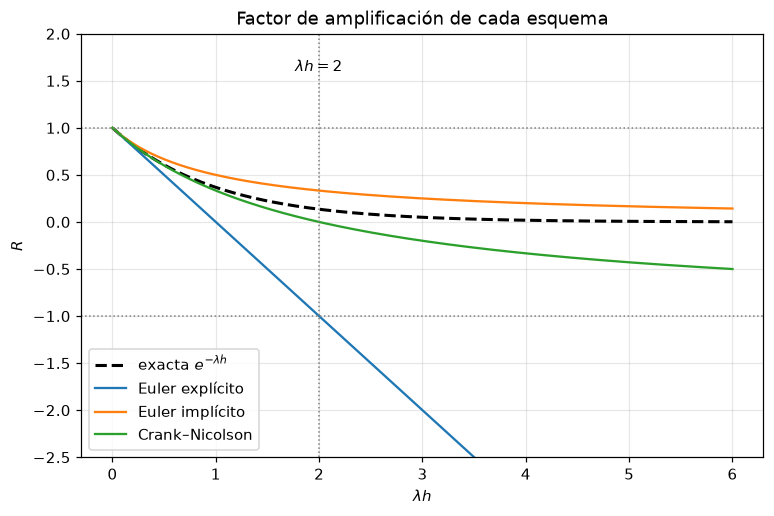

In [4]:
x = np.linspace(0, 6, 601)
zz = -x

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(x, np.exp(zz), "k--", lw=2, label=r"exacta $e^{-\lambda h}$")
ax.plot(x, R_FE(zz), label="Euler explícito")
ax.plot(x, R_BE(zz), label="Euler implícito")
ax.plot(x, R_CN(zz), label="Crank–Nicolson")
for y in (1, -1):
    ax.axhline(y, color="gray", ls=":", lw=1)
ax.axvline(2, color="gray", ls=":", lw=1)
ax.annotate(r"$\lambda h = 2$", (2, 1.6), ha="center")
ax.set_ylim(-2.5, 2)
ax.set_xlabel(r"$\lambda h$")
ax.set_ylabel(r"$R$")
ax.set_title("Factor de amplificación de cada esquema")
ax.legend()
fig.savefig(FIG / "p1_R_vs_lh.pdf", bbox_inches="tight")
plt.show()

## 4. ¿Qué pasa cuando $\lambda h \to \infty$?

Se grafica $|R|$ en escala logarítmica. Euler explícito crece sin límite, CN se acerca a 1 y Euler implícito tiende a 0, igual que la exacta.

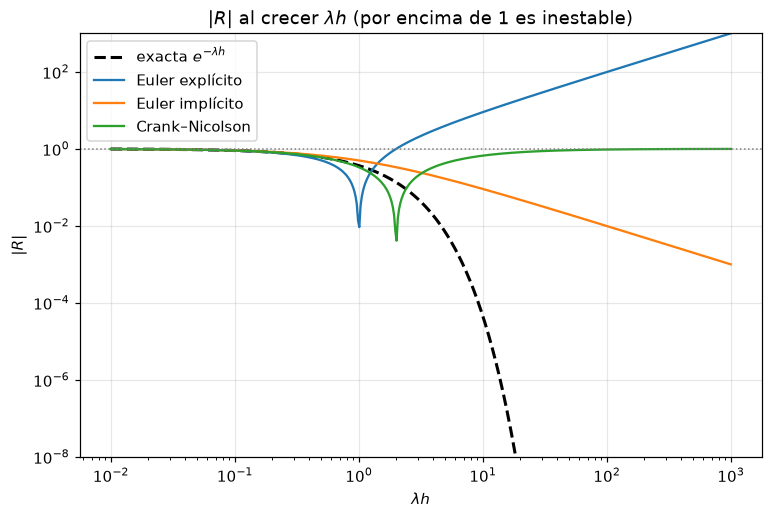

In [5]:
# >>> CAMBIA AQUÍ: rango de λh en potencias de 10 (de 10^-2 a 10^3).
x = np.logspace(-2, 3, 500)
zz = -x

fig, ax = plt.subplots(figsize=(8, 5))
ax.loglog(x, np.exp(zz), "k--", lw=2, label=r"exacta $e^{-\lambda h}$")
ax.loglog(x, np.abs(R_FE(zz)), label="Euler explícito")
ax.loglog(x, np.abs(R_BE(zz)), label="Euler implícito")
ax.loglog(x, np.abs(R_CN(zz)), label="Crank–Nicolson")
ax.axhline(1, color="gray", ls=":", lw=1)
ax.set_ylim(1e-8, 1e3)
ax.set_xlabel(r"$\lambda h$")
ax.set_ylabel(r"$|R|$")
ax.set_title(r"$|R|$ al crecer $\lambda h$ (por encima de 1 es inestable)")
ax.legend()
fig.savefig(FIG / "p1_R_limite.pdf", bbox_inches="tight")
plt.show()

## 5. La población $N_n = R^n N_0$ para distintos $\lambda h$

Cada columna es un valor de $\lambda h$ de la tabla. Se grafica $N_n$ contra el número de paso $n$ (eje $N$ recortado a $\pm150$; Euler explícito se sale porque crece mucho).

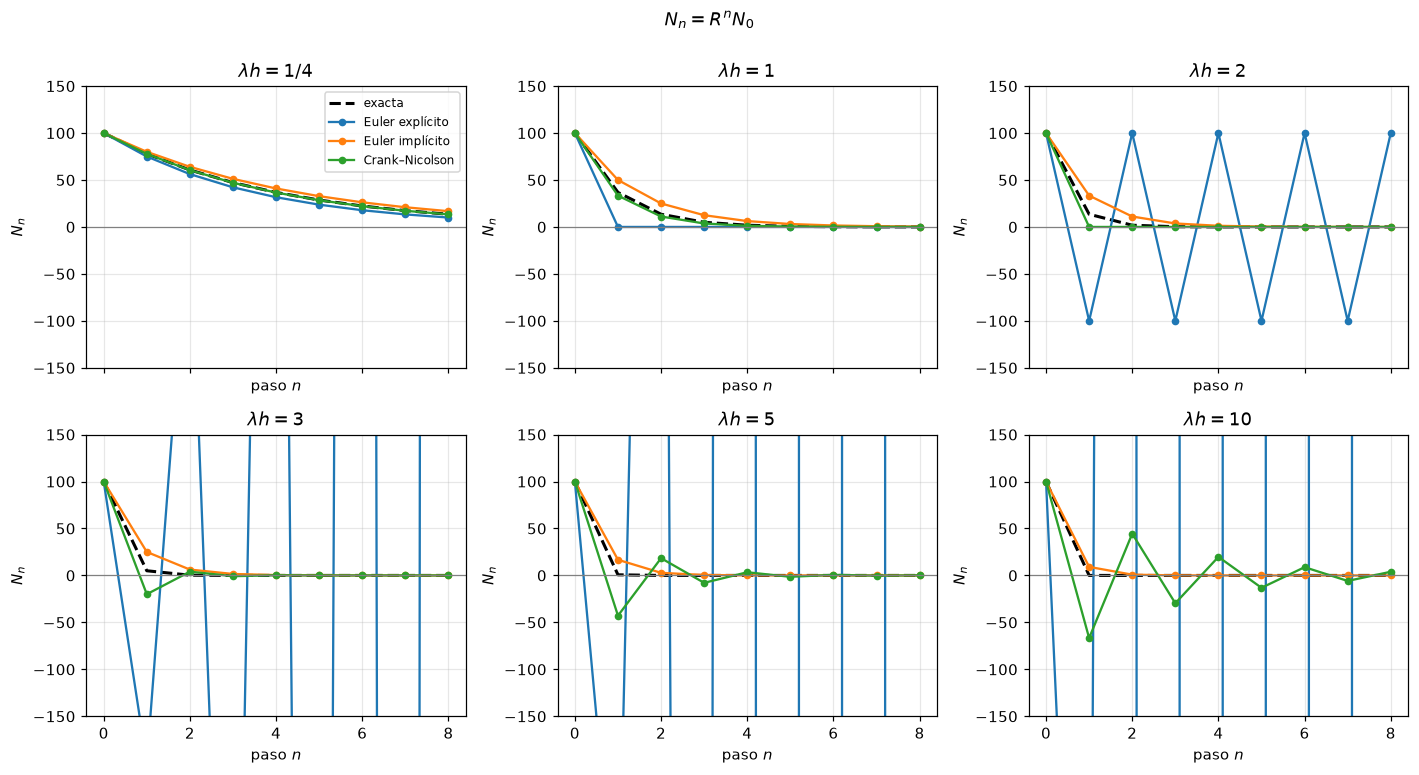

In [6]:
# >>> CAMBIA AQUÍ: los 6 valores de λh (uno por gráfica) y cuántos pasos n se dibujan.
casos = [Fraction(1, 4), 1, 2, 3, 5, 10]
n = np.arange(0, 9)

fig, axs = plt.subplots(2, 3, figsize=(13, 7), sharex=True)
for ax, x in zip(axs.ravel(), casos):
    x = float(x)
    zz = -x
    ax.plot(n, N0 * np.exp(zz * n), "k--", lw=2, label="exacta")
    for nombre, R in esquemas.items():
        ax.plot(n, N0 * R(zz) ** n, "o-", ms=4, label=nombre)
    ax.axhline(0, color="gray", lw=0.8)
    ax.set_ylim(-150, 150)   # >>> CAMBIA AQUÍ: recorte del eje N (Euler explícito se sale)
    ax.set_title(rf"$\lambda h = {frac(Fraction(x).limit_denominator(10))}$")
    ax.set_xlabel("paso $n$")
    ax.set_ylabel(r"$N_n$")
axs[0, 0].legend(fontsize=8)
fig.suptitle(r"$N_n = R^n N_0$", y=1.0)
fig.tight_layout()
fig.savefig(FIG / "p1_poblacion.pdf", bbox_inches="tight")
plt.show()

## 5b. El decaimiento real: $N(t)$ contra $t$

Aquí sí se ve la exponencial decreciendo. Se compara la solución exacta $N(t)=N_0e^{-\lambda t}$ (curva continua) con lo que da cada esquema en los instantes $t_n = nh$, para tres tamaños de paso.

El eje $N$ está recortado a $\pm120$: cuando Euler explícito se sale, es porque su población ya creció muy por encima de $N_0$.

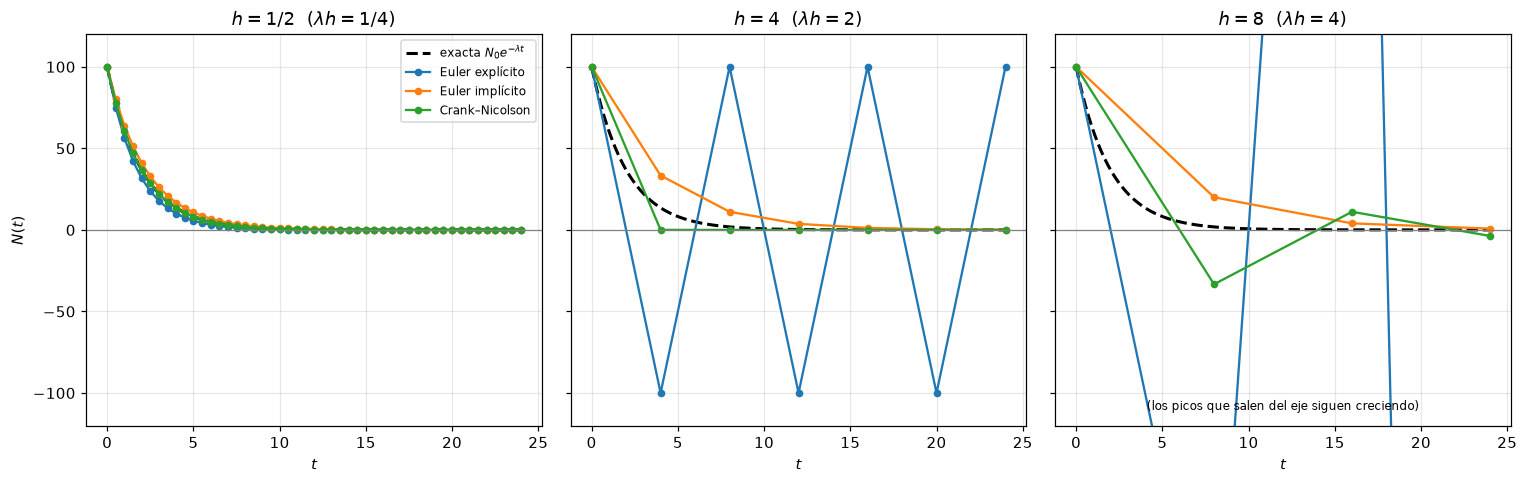

In [7]:

T = 24.0
t = np.linspace(0, T, 400)
casos_h = [Fraction(1, 2), 4, 8]

fig, axs = plt.subplots(1, 3, figsize=(14, 4.5), sharey=True)
for ax, h in zip(axs, casos_h):
    h = float(h)
    zz = -lam * h
    n = np.arange(0, int(round(T / h)) + 1)
    ax.plot(t, N0 * np.exp(-lam * t), "k--", lw=2, label=r"exacta $N_0e^{-\lambda t}$")
    for nombre, R in esquemas.items():
        ax.plot(n * h, N0 * R(zz) ** n, "o-", ms=4, label=nombre)
    ax.axhline(0, color="gray", lw=0.8)
    ax.set_ylim(-120, 120)
    ax.set_title(rf"$h={frac(Fraction(h))}$  ($\lambda h={frac(Fraction(lam*h))}$)")
    ax.set_xlabel("$t$")
axs[0].set_ylabel(r"$N(t)$")
axs[0].legend(fontsize=8)
axs[2].text(0.5, 0.04, "(los picos que salen del eje siguen creciendo)", transform=axs[2].transAxes, ha="center", fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "p1_decaimiento.pdf", bbox_inches="tight")
plt.show()

## Problema 2: CN es de orden 3 local y 2 global

$N' = -\lambda N$, $\lambda = 1$, $N_0 = 100$, $T = 1$.  Con CN, $N_{n+1} = R_{\mathrm{CN}}(-\lambda h)\,N_n$ y

$$R_{\mathrm{CN}}(z) = \frac{1 + z/2}{1 - z/2}, \qquad R_{\mathrm{CN}}(-\lambda h) = \frac{2 - \lambda h}{2 + \lambda h}.$$

Este notebook calcula las tablas de los incisos (b) y (c), hace la gráfica log–log del inciso (d)
y la guarda en `latex/figuras/p02_loglog.pdf`.

In [8]:
lam2, N0_2, T2 = 1.0, 100.0, 1.0

### Inciso (a)

In [9]:
import sympy as sp
zs = sp.symbols("z")
sp.series(sp.exp(zs) - (1 + zs/2) / (1 - zs/2), zs, 0, 6)

-z**3/12 - z**4/12 - 13*z**5/240 + O(z**6)

### Inciso (b): error local

Un solo paso desde $t = 0$ (por unidad de $N_0$): $e_{\mathrm{loc}}(h) = |e^{-\lambda h} - R_{\mathrm{CN}}(-\lambda h)|$.

In [10]:
h_loc = np.array([0.40, 0.20, 0.10, 0.05])
R_loc = R_CN(-lam2 * h_loc)
e_loc = np.abs(np.exp(-lam2 * h_loc) - R_loc)

rconv_loc = np.r_[np.nan, e_loc[:-1] / e_loc[1:]]
p_loc = np.log(rconv_loc) / np.log(2)

tab_loc = pd.DataFrame({"h": h_loc, "R_CN": R_loc, "e^{-h}": np.exp(-lam2 * h_loc),
                        "e_loc": e_loc, "h^3/12": h_loc**3 / 12,
                        "e_loc(2h)/e_loc(h)": rconv_loc, "p_loc": p_loc})
tab_loc.style.format({"h": "{:.2f}", "R_CN": "{:.12f}", "e^{-h}": "{:.12f}", "e_loc": "{:.6e}",
                      "h^3/12": "{:.6e}", "e_loc(2h)/e_loc(h)": "{:.6f}", "p_loc": "{:.6f}"}, na_rep="---").hide(axis="index")

h,R_CN,e^{-h},e_loc,h^3/12,e_loc(2h)/e_loc(h),p_loc
0.40,0.666666666667,0.670320046036,3.653379e-03,5.333333e-03,---,---
0.20,0.818181818182,0.818730753078,5.489349e-04,6.666667e-04,6.655396,2.734525
0.10,0.904761904762,0.904837418036,7.551327e-05,8.333333e-05,7.269383,2.861833
0.05,0.951219512195,0.951229424501,9.912306e-06,1.041667e-05,7.618134,2.929438


### Inciso (c): error global en $T = 1$

$n = T/h$ pasos: $N_n = R^n N_0$. El enunciado compara contra $e^{-\lambda}$ (la exacta entre $N_0$), así que
$E(h) = |N_{T/h}/N_0 - e^{-\lambda T}|$. Con $N_0 = 100$ los errores salen $\times 100$ y el orden no cambia.

In [11]:
h_glo = np.array([1/2, 1/4, 1/8, 1/16])
n_glo = np.rint(T2 / h_glo).astype(int)
R_glo = R_CN(-lam2 * h_glo)
Nn = N0_2 * R_glo**n_glo                      # N_{T2/h} con N_0 = 100
E = np.abs(Nn / N0_2 - np.exp(-lam2 * T2))     # por unidad de N_0

rconv_glo = np.r_[np.nan, E[:-1] / E[1:]]
p_glo = np.log(rconv_glo) / np.log(2)

tab_glo = pd.DataFrame({"h": ["1/2", "1/4", "1/8", "1/16"], "n": n_glo, "R_CN": R_glo,
                        "N_n (N0=100)": Nn, "E(h)": E, "e^{-1} h^2/12": np.exp(-1) * h_glo**2 / 12,
                        "E(2h)/E(h)": rconv_glo, "p_glob": p_glo})
tab_glo.style.format({"R_CN": "{:.12f}", "N_n (N0=100)": "{:.7f}", "E(h)": "{:.6e}",
                      "e^{-1} h^2/12": "{:.6e}", "E(2h)/E(h)": "{:.6f}", "p_glob": "{:.6f}"}, na_rep="---").hide(axis="index")

h,n,R_CN,N_n (N0=100),E(h),e^{-1} h^2/12,E(2h)/E(h),p_glob
1/2,2,0.600000000000,36.0000000,7.879441e-03,7.664155e-03,---,---
1/4,4,0.777777777778,36.5950312,1.929129e-03,1.916039e-03,4.084456,2.030144
1/8,8,0.882352941176,36.7399619,4.798223e-04,4.790097e-04,4.020506,2.007377
1/16,16,0.939393939394,36.7759638,1.198031e-04,1.197524e-04,4.005090,2.001835


### Inciso (d): gráfica log–log

Las líneas punteadas son las predicciones teóricas: $h^3/12$ (pendiente 3, inciso a) y $e^{-1}h^2/12$ (pendiente 2, inciso d).

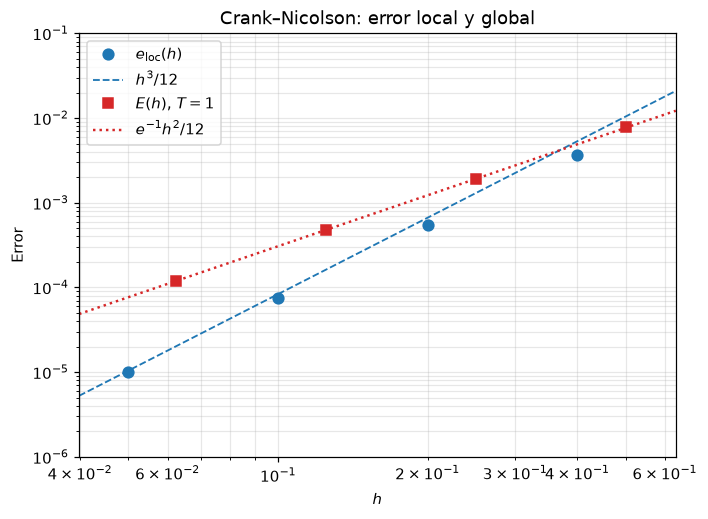

In [12]:
hh = np.logspace(-1.4, -0.2, 100)

fig, ax = plt.subplots(figsize=(7, 5))
ax.loglog(h_loc, e_loc, "o", ms=7, color="C0", label=r"$e_{\mathrm{loc}}(h)$")
ax.loglog(hh, hh**3 / 12, "--", color="C0", lw=1.2, label=r"$h^3/12$")
ax.loglog(h_glo, E, "s", ms=7, color="C3", label=r"$E(h)$, $T = 1$")
ax.loglog(hh, np.exp(-1) * hh**2 / 12, ":", color="C3", lw=1.6, label=r"$e^{-1}h^2/12$")

ax.set_xlim(10**-1.4, 10**-0.2)
ax.set_ylim(1e-6, 1e-1)
ax.set_xlabel(r"$h$")
ax.set_ylabel("Error")
ax.set_title("Crank–Nicolson: error local y global")
ax.grid(True, which="both", alpha=0.3)
ax.legend(loc="upper left")

fig.savefig(FIG / "p02_loglog.pdf", bbox_inches="tight")
fig.savefig(FIG / "p02_loglog.png", dpi=200, bbox_inches="tight")
plt.show()

In [13]:
for h, e in zip(h_glo, E):
    print(f"h = 1/{round(1/h):2d}   E = {e:.6e}   estimación = {np.exp(-1)*h**2/12:.6e}   cota = {h**2/12:.6e}")

h = 1/ 2   E = 7.879441e-03   estimación = 7.664155e-03   cota = 2.083333e-02
h = 1/ 4   E = 1.929129e-03   estimación = 1.916039e-03   cota = 5.208333e-03
h = 1/ 8   E = 4.798223e-04   estimación = 4.790097e-04   cota = 1.302083e-03
h = 1/16   E = 1.198031e-04   estimación = 1.197524e-04   cota = 3.255208e-04


## Problema 3: Decaimiento con fuente

$N' = -\lambda N + S$, con $\lambda = 2$, $S = 4$, $N_0 = 0$ y $h = \tfrac14$. Se compara Crank–Nicolson con fuente,
$N_{n+1} = R\,N_n + \dfrac{hS}{1 + \lambda h/2}$, y Euler implícito contra la exacta $N(t) = \dfrac{S}{\lambda}\left(1 - e^{-\lambda t}\right)$.
La tabla se guarda en `latex/tablas/p3_b_todos.tex` y la figura en `latex/figuras/p3_solucion.pdf`.

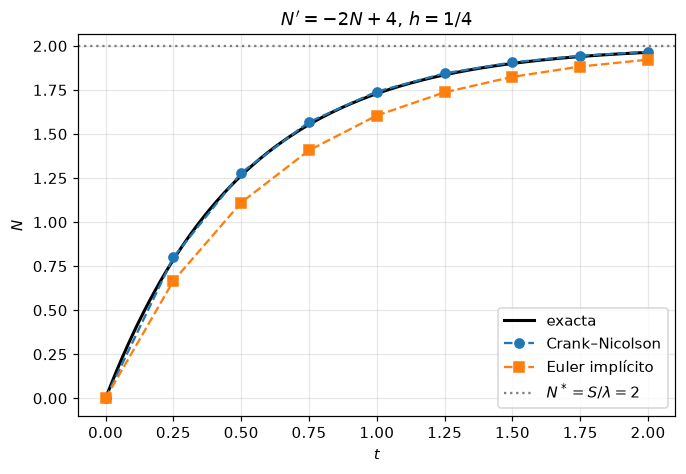

In [14]:
# Problema 3: N' = -lambda N + S, CN y Euler implícito contra la exacta
# >>> CAMBIA AQUÍ: lam3 = λ, S3 = fuente, N0_3 = población inicial, h3 = paso, T3 = tiempo final.
# (Con sufijo 3 para no pisar las variables de los Problemas 1 y 2.)
TAB = Path.cwd().parent / "latex" / "tablas"     # las tablas se guardan aquí para LaTeX
TAB.mkdir(parents=True, exist_ok=True)

lam3, S3, N0_3, h3, T3 = 2.0, 4.0, 0.0, 0.25, 2.0
Nstar = S3 / lam3
n = np.arange(0, int(round(T3 / h3)) + 1)
t = n * h3

R3 = (1 - lam3*h3/2) / (1 + lam3*h3/2)
c3 = h3*S3 / (1 + lam3*h3/2)
N_cn = np.zeros_like(t); N_be = np.zeros_like(t)
N_cn[0] = N_be[0] = N0_3
for k in range(len(t) - 1):
    N_cn[k+1] = R3*N_cn[k] + c3
    N_be[k+1] = (N_be[k] + h3*S3) / (1 + lam3*h3)
N_ex = Nstar * (1 - np.exp(-lam3*t))

with open(TAB / "p3_b_todos.tex", "w") as f:
    f.write("\\begin{tabular}{cccccc}\\toprule\n")
    f.write("$n$ & $t_n$ & CN & Euler impl. & exacta & $|N(t_n) - N_n^{\\mathrm{CN}}|$\\\\\\midrule\n")
    for k in range(len(t)):
        f.write(f"{n[k]} & {t[k]:.2f} & {N_cn[k]:.6f} & {N_be[k]:.6f} & {N_ex[k]:.6f} & {abs(N_ex[k]-N_cn[k]):.6f}\\\\\n")
    f.write("\\bottomrule\n\\end{tabular}\n")

tt = np.linspace(0, T3, 300)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(tt, Nstar*(1 - np.exp(-lam3*tt)), "k-", lw=2, label="exacta")
ax.plot(t, N_cn, "o--", label="Crank–Nicolson")
ax.plot(t, N_be, "s--", label="Euler implícito")
ax.axhline(Nstar, color="gray", ls=":", label=r"$N^* = S/\lambda = 2$")
ax.set_xlabel(r"$t$"); ax.set_ylabel(r"$N$")
ax.set_title(r"$N' = -2N + 4$, $h = 1/4$")
ax.grid(alpha=0.3); ax.legend()
fig.savefig(FIG / "p3_solucion.pdf", bbox_inches="tight")
plt.show()


In [15]:
# Problema 3 (d): error global en T = 1 y orden observado (CN)
# >>> CAMBIA AQUÍ: lam3 y S3 (λ y fuente), T3d (tiempo final) y la lista de pasos h.
# (Nombres con sufijo 3 para no pisar las variables de los Problemas 1 y 2.)
lam3, S3, T3d = 2.0, 4.0, 1.0
N_T = (S3/lam3) * (1 - np.exp(-lam3*T3d))
E3 = []
for h_d in [1/2, 1/4, 1/8]:
    R_d = (1 - lam3*h_d/2) / (1 + lam3*h_d/2)
    c_d = h_d*S3 / (1 + lam3*h_d/2)
    N_d = 0.0
    for _ in range(int(round(T3d/h_d))):
        N_d = R_d*N_d + c_d
    E3.append(abs(N_d - N_T))
    print(f"h = {h_d:<6}  N_T/h = {N_d:.6f}   E = {E3[-1]:.6e}")
for k in range(1, len(E3)):
    q = E3[k-1] / E3[k]
    print(f"E(2h)/E(h) = {q:.6f}   p_glob = {np.log(q)/np.log(2):.6f}")


h = 0.5     N_T/h = 1.777778   E = 4.844834e-02
h = 0.25    N_T/h = 1.740800   E = 1.147057e-02
h = 0.125   N_T/h = 1.732161   E = 2.831304e-03
E(2h)/E(h) = 4.223710   p_glob = 2.078511
E(2h)/E(h) = 4.051337   p_glob = 2.018398


## Problema 4: Difusión 1D con condiciones de Dirichlet

$A=\operatorname{tridiag}(-1,4,-1)$ de $4\times4$ y $\mathbf{b}=(4,4,4,4)$.

### (b) Construcción de $A$ y $\mathbf{b}$

Se verifica que $A$ es simétrica, que $\mathbf{x}^TA\mathbf{x}>0$ para algunos $\mathbf{x}\neq 0$ aleatorios y que todos sus valores propios son positivos.

In [16]:
import sympy as sp

# >>> CAMBIA AQUÍ: n (número de nodos interiores) y el valor de la fuente en b.
n4 = 4
A4 = sp.Matrix(n4, n4, lambda i, j: 4 if i == j else (-1 if abs(i - j) == 1 else 0))
b4 = sp.Matrix([4] * n4)
sp.pprint(A4); print(); sp.pprint(b4.T)

print("\nA == A.T:", A4 == A4.T)

rng = np.random.default_rng(0)
A4_np = np.array(A4.tolist(), dtype=float)
print("\nx^T A x para vectores aleatorios no nulos:")
for _ in range(5):
    x = rng.standard_normal(n4)
    q = x @ A4_np @ x
    print(f"  x^T A x = {q:.6f}   > 0: {q > 0}")

lam_A = np.linalg.eigvalsh(A4_np)
print("\nvalores propios de A:", [f"{v:.6f}" for v in lam_A])
print("todos positivos:", bool(np.all(lam_A > 0)))


⎡4   -1  0   0 ⎤
⎢              ⎥
⎢-1  4   -1  0 ⎥
⎢              ⎥
⎢0   -1  4   -1⎥
⎢              ⎥
⎣0   0   -1  4 ⎦

[4  4  4  4]

A == A.T: True

x^T A x para vectores aleatorios no nulos:
  x^T A x = 1.885684   > 0: True
  x^T A x = 9.034648   > 0: True
  x^T A x = 6.639916   > 0: True
  x^T A x = 26.781325   > 0: True
  x^T A x = 5.667988   > 0: True

valores propios de A: ['2.381966', '3.381966', '4.618034', '5.618034']
todos positivos: True


### (c) Gauss sin pivoteo (exacto)

$A=LU$ con `sympy` (fracciones exactas).

In [17]:
# Gauss sin pivoteo, exacto (con Rational)
L4 = sp.eye(n4); U4 = A4.copy()
for k in range(n4 - 1):
    for i in range(k + 1, n4):
        L4[i, k] = U4[i, k] / U4[k, k]
        U4[i, :] = U4[i, :] - L4[i, k] * U4[k, :]

print("L ="); sp.pprint(L4)
print("\nU ="); sp.pprint(U4)
print("\nL*U == A:", L4 * U4 == A4)
print("debajo de la diagonal de L:", [L4[i+1, i] for i in range(n4 - 1)])
print("diagonal de U:", [U4[i, i] for i in range(n4)])


L =
⎡ 1      0     0    0⎤
⎢                    ⎥
⎢-1/4    1     0    0⎥
⎢                    ⎥
⎢ 0    -4/15   1    0⎥
⎢                    ⎥
⎢             -15    ⎥
⎢ 0      0    ────  1⎥
⎣              56    ⎦

U =
⎡4   -1   0    0 ⎤
⎢                ⎥
⎢0  15/4  -1   0 ⎥
⎢                ⎥
⎢         56     ⎥
⎢0   0    ──  -1 ⎥
⎢         15     ⎥
⎢                ⎥
⎢             209⎥
⎢0   0    0   ───⎥
⎣             56 ⎦

L*U == A: True
debajo de la diagonal de L: [-1/4, -4/15, -15/56]
diagonal de U: [4, 15/4, 56/15, 209/56]


### (d) Factorización $LDL^T$ (exacta)

Se calcula con ciclos, columna por columna, y después se compara con $U$ de Gauss: $U = DL^T$.

In [18]:
# LDL^T exacto con ciclos, columna por columna (sin usar la U de Gauss):
#   d_j  = a_jj - sum_{k<j} l_jk^2 d_k
#   l_ij = ( a_ij - sum_{k<j} l_ik l_jk d_k ) / d_j        (i > j)
L_ldl = sp.eye(n4)
d_ldl = [None] * n4
for j in range(n4):
    s = A4[j, j]
    for k in range(j):
        s -= L_ldl[j, k]**2 * d_ldl[k]
    d_ldl[j] = s
    for i in range(j + 1, n4):
        s = A4[i, j]
        for k in range(j):
            s -= L_ldl[i, k] * L_ldl[j, k] * d_ldl[k]
        L_ldl[i, j] = s / d_ldl[j]

D4 = sp.diag(*d_ldl)
print("D ="); sp.pprint(D4)
print("\nL ="); sp.pprint(L_ldl)

# Verificaciones
print("\nL*D*L.T == A:", L_ldl * D4 * L_ldl.T == A4)
print("U == D*L.T  :", U4 == D4 * L_ldl.T)          # U viene de Gauss (inciso c)
print("L (LDL^T) == L (Gauss):", L_ldl == L4, "  D == diag(U):", D4 == sp.diag(*[U4[i, i] for i in range(n4)]))


D =
⎡4   0    0    0 ⎤
⎢                ⎥
⎢0  15/4  0    0 ⎥
⎢                ⎥
⎢         56     ⎥
⎢0   0    ──   0 ⎥
⎢         15     ⎥
⎢                ⎥
⎢             209⎥
⎢0   0    0   ───⎥
⎣             56 ⎦

L =
⎡ 1      0     0    0⎤
⎢                    ⎥
⎢-1/4    1     0    0⎥
⎢                    ⎥
⎢ 0    -4/15   1    0⎥
⎢                    ⎥
⎢             -15    ⎥
⎢ 0      0    ────  1⎥
⎣              56    ⎦

L*D*L.T == A: True
U == D*L.T  : True
L (LDL^T) == L (Gauss): True   D == diag(U): True


### (e) Cholesky

$A=GG^T$ calculada con ciclos (fórmulas de $g_{jj}$ y $g_{ij}$ en los comentarios); `np.linalg.cholesky` solo se usa para verificar.

In [19]:
import math

# Cholesky A = G G^T con ciclos (G triangular inferior), columna por columna:
#   g_jj = sqrt( a_jj - sum_{k<j} g_jk^2 )
#   g_ij = ( a_ij - sum_{k<j} g_ik g_jk ) / g_jj          (i > j)
G4 = np.zeros((n4, n4))
for j in range(n4):
    s = A4_np[j, j]
    for k in range(j):
        s -= G4[j, k]**2
    G4[j, j] = math.sqrt(s)                 # requiere s > 0 (A definida positiva)
    for i in range(j + 1, n4):
        s = A4_np[i, j]
        for k in range(j):
            s -= G4[i, k] * G4[j, k]
        G4[i, j] = s / G4[j, j]

print("G =")
for i in range(n4):
    print("  " + "  ".join(f"{G4[i, j]:>10.6f}" for j in range(n4)))

# Verificaciones
print("\nG @ G.T ≈ A:", np.allclose(G4 @ G4.T, A4_np))
print("coincide con np.linalg.cholesky:", np.allclose(G4, np.linalg.cholesky(A4_np)))
print("g_jj^2 = d_j (de LDL^T):", [f"{G4[j, j]**2:.6f} vs {float(D4[j, j]):.6f}" for j in range(n4)])


G =
    2.000000    0.000000    0.000000    0.000000
   -0.500000    1.936492    0.000000    0.000000
    0.000000   -0.516398    1.932184    0.000000
    0.000000    0.000000   -0.517549    1.931875

G @ G.T ≈ A: True
coincide con np.linalg.cholesky: True
g_jj^2 = d_j (de LDL^T): ['4.000000 vs 4.000000', '3.750000 vs 3.750000', '3.733333 vs 3.733333', '3.732143 vs 3.732143']


In [20]:
# Cholesky directo con NumPy: devuelve G triangular inferior tal que A = G G^T
# (lanza LinAlgError si A no es definida positiva)
G4_np = np.linalg.cholesky(A4_np)

print("G (np.linalg.cholesky) =")
for i in range(n4):
    print("  " + "  ".join(f"{G4_np[i, j]:>10.6f}" for j in range(n4)))

print("\nG @ G.T ≈ A:", np.allclose(G4_np @ G4_np.T, A4_np))
print("coincide con G de los ciclos:", np.allclose(G4_np, G4))


G (np.linalg.cholesky) =
    2.000000    0.000000    0.000000    0.000000
   -0.500000    1.936492    0.000000    0.000000
    0.000000   -0.516398    1.932184    0.000000
    0.000000    0.000000   -0.517549    1.931875

G @ G.T ≈ A: True
coincide con G de los ciclos: True


### (f) Resolver con $LDL^T$

$L\mathbf{z}=\mathbf{b}$ (adelante), $D\mathbf{y}=\mathbf{z}$ (diagonal) y $L^T\boldsymbol{\varphi}=\mathbf{y}$ (atrás), todo exacto.

In [21]:
# Resolver A phi = b con LDL^T, exacto: L z = b (adelante), D y = z (diagonal), L^T phi = y (atrás)
z4 = sp.zeros(n4, 1)
for i in range(n4):
    z4[i] = b4[i] - sum((L4[i, j] * z4[j] for j in range(i)), sp.Integer(0))

y4 = sp.Matrix([z4[i] / D4[i, i] for i in range(n4)])

phi4 = sp.zeros(n4, 1)
for i in range(n4 - 1, -1, -1):
    phi4[i] = y4[i] - sum((L4[j, i] * phi4[j] for j in range(i + 1, n4)), sp.Integer(0))

for nombre, v in (("z (adelante)", z4), ("y (diagonal)", y4), ("phi (atrás)", phi4)):
    print(f"{nombre:13s}= {list(v)}")
print("phi decimales =", [f"{float(v):.6f}" for v in phi4])
print("\nA*phi == b:", A4 * phi4 == b4)
print("phi1 == phi4:", phi4[0] == phi4[3])
print("phi2 == phi3:", phi4[1] == phi4[2])


z (adelante) = [4, 5, 16/3, 38/7]
y (diagonal) = [1, 4/3, 10/7, 16/11]
phi (atrás)  = [16/11, 20/11, 20/11, 16/11]
phi decimales = ['1.454545', '1.818182', '1.818182', '1.454545']

A*phi == b: True
phi1 == phi4: True
phi2 == phi3: True


### (g) Costo densa vs tridiagonal

Sistema $A\mathbf{x}=\mathbf{b}$ con $A=\operatorname{tridiag}(-1,4,-1)$ de $n\times n$ y $\mathbf{b}=(1,\dots,1)$. Se cuentan las operaciones de
(a) Gauss sin pivoteo en matriz densa y (b) $LDL^T$ de tridiagonal (cada $\times,\ \div,\ +,\ -$ cuenta 1), y se mide el tiempo con
`np.linalg.solve` (densa) y `scipy.linalg.solve_banded` (tridiagonal). Para $n$ grande se usan las fórmulas
$T_{\mathrm{densa}}=\tfrac23 n^3+\tfrac32 n^2-\tfrac76 n$ y $T_{\mathrm{tri}}=8n-7$. La última salida es la tabla en formato LaTeX.

In [22]:
import time
import scipy.linalg as sla

# >>> CAMBIA AQUÍ: los tamaños n que se miden y cuántas repeticiones se hacen en cada uno
# (con n chica el tiempo es muy pequeño, por eso se repite y se toma el mínimo).
ns_p4 = [4, 100, 1000, 3000]
reps_p4 = {4: 2000, 100: 200, 1000: 5, 3000: 3}

# ---------- 1. Sistema: A = tridiag(-1, 4, -1), b = (1, ..., 1) ----------
def sistema_p4(n):
    A = 4.0*np.eye(n) - np.eye(n, k=1) - np.eye(n, k=-1)
    return A, np.ones(n)

# ---------- 2. Conteo de operaciones (cada *, /, +, - suma 1) ----------
def ops_densa_contador(A, b):
    """Gauss sin pivoteo (matriz densa) + sustitución hacia adelante y hacia atrás."""
    A = A.copy(); b = b.copy(); n = len(b); ops = 0
    for k in range(n - 1):                      # eliminación
        for i in range(k + 1, n):
            m = A[i, k] / A[k, k]; ops += 1                     # división
            for j in range(k + 1, n):
                A[i, j] -= m * A[k, j]; ops += 2                # producto y resta
            b[i] -= m * b[k]; ops += 2
    x = np.zeros(n)
    for i in range(n - 1, -1, -1):              # sustitución hacia atrás
        s = b[i]
        for j in range(i + 1, n):
            s -= A[i, j] * x[j]; ops += 2
        x[i] = s / A[i, i]; ops += 1
    return x, ops

def ops_tridiag_contador(sub, diag, sup, b):
    """LDL^T de tridiagonal simétrica: adelante, diagonal y atrás."""
    d = diag.copy(); e = sup.copy(); y = b.copy(); n = len(b); ops = 0
    l = np.zeros(n - 1)
    for i in range(1, n):                       # factorización A = L D L^T
        l[i-1] = e[i-1] / d[i-1]; ops += 1
        d[i] -= l[i-1] * e[i-1]; ops += 2
    for i in range(1, n):                       # L y = b
        y[i] -= l[i-1] * y[i-1]; ops += 2
    z = y / d; ops += n                         # D z = y
    x = z.copy()
    for i in range(n - 2, -1, -1):              # L^T x = z
        x[i] -= l[i] * x[i+1]; ops += 2
    return x, ops

# Fórmulas (enteros exactos): T_densa = 2/3 n^3 + 3/2 n^2 - 7/6 n,  T_tri = 8n - 7
T_densa = lambda n: (4*n**3 + 9*n**2 - 7*n) // 6
T_tri   = lambda n: 8*n - 7

print("Verificación de los contadores:")
for n in (4, 100):
    A, b = sistema_p4(n)
    x_d, o_d = ops_densa_contador(A, b)
    x_t, o_t = ops_tridiag_contador(-np.ones(n-1), 4.0*np.ones(n), -np.ones(n-1), b)
    assert np.allclose(x_d, np.linalg.solve(A, b)) and np.allclose(x_t, x_d)
    assert (o_d, o_t) == (T_densa(n), T_tri(n))
    print(f"n = {n:4d}   densa = {o_d:8d} (fórmula {T_densa(n)})   tridiagonal = {o_t:5d} (fórmula {T_tri(n)})")

# ---------- 3. Cronómetro: mínimo de varias repeticiones ----------
def tiempo_min(f, reps):
    mejor = float("inf")
    for _ in range(reps):
        t0 = time.perf_counter(); f(); mejor = min(mejor, time.perf_counter() - t0)
    return mejor

# ---------- 4. Tabla lista para pegar en LaTeX ----------
miles = lambda m: f"{m:,}".replace(",", r"\,")     # 681550 -> 681\,550
print("\nTabla (pegar en LaTeX):")
for n in ns_p4:
    A, b = sistema_p4(n)
    banda = np.zeros((3, n)); banda[0, 1:] = -1; banda[1] = 4; banda[2, :-1] = -1
    t_den = tiempo_min(lambda: np.linalg.solve(A, b), reps_p4[n])
    t_tri = tiempo_min(lambda: sla.solve_banded((1, 1), banda, b), reps_p4[n])
    print(f"{n} & {miles(T_densa(n))} & {miles(T_tri(n))} & {t_den:.6f} & {t_tri:.6f} \\\\")


Verificación de los contadores:
n =    4   densa =       62 (fórmula 62)   tridiagonal =    25 (fórmula 25)
n =  100   densa =   681550 (fórmula 681550)   tridiagonal =   793 (fórmula 793)

Tabla (pegar en LaTeX):


4 & 62 & 25 & 0.000010 & 0.000036 \\
100 & 681\,550 & 793 & 0.000114 & 0.000044 \\
1000 & 668\,165\,500 & 7\,993 & 0.013335 & 0.000071 \\


3000 & 18\,013\,496\,500 & 23\,993 & 0.323195 & 0.000110 \\


## Problema 5: Difusión con condición de simetría y Robin

$-D\varphi'' + \Sigma_a\varphi = S$ en $[0,1]$, con $\varphi'(0)=0$ (simetría) y $D\varphi'(1)+\gamma\varphi(1)=0$ (Robin).
Se discretiza con diferencias centradas y nodos fantasma en los extremos.

### Inciso (a): verificación simbólica

Taylor de las diferencias centradas y ecuaciones de los nodos $0$ y $N$ (con nodo fantasma).

In [23]:
import sympy as sp
import numpy as np

D, Sa, S, h, gamma = sp.symbols("D S_a S h gamma", positive=True)
phim1, phi0, phi1, phiN1, phiN, phiN1g = sp.symbols("phim1 phi0 phi1 phiN1 phiN phiN1g")

In [24]:
# Taylor de una f(x) genérica alrededor de h = 0
x0 = sp.symbols("x0")
f = sp.Function("f")
fp = sp.series(f(x0 + h), h, 0, 6).removeO().doit()
fm = sp.series(f(x0 - h), h, 0, 6).removeO().doit()

d1 = sp.expand((fp - fm) / (2*h))
d2 = sp.expand((fp - 2*f(x0) + fm) / h**2)
print("(f(x0+h) - f(x0-h))/(2h)            =", d1, " + O(h^4)")
print("(f(x0+h) - 2f(x0) + f(x0-h))/h^2    =", d2, " + O(h^4)")

# lo que se espera: f' + h^2/6 f''' (y f'' + h^2/12 f'''')
esp1 = sp.diff(f(x0), x0) + h**2/6 * sp.diff(f(x0), x0, 3)
esp2 = sp.diff(f(x0), x0, 2) + h**2/12 * sp.diff(f(x0), x0, 4)
# la serie llega hasta h^5 en f(x0±h), así que las diferencias son exactas hasta h^3 (resp. h^2):
# se compara quitando los términos de orden h^4 (que son los O(h^4) del enunciado)
ok_taylor1 = sp.simplify(d1 - esp1 - h**4/120 * sp.diff(f(x0), x0, 5)) == 0
ok_taylor2 = sp.simplify(d2 - esp2) == 0
print("\ncentrada 1ª derivada = f' + h^2/6 f''' + O(h^4):", ok_taylor1)
print("centrada 2ª derivada = f'' + h^2/12 f'''' + O(h^4):", ok_taylor2)

(f(x0+h) - f(x0-h))/(2h)            = h**4*Derivative(f(x0), (x0, 5))/120 + h**2*Derivative(f(x0), (x0, 3))/6 + Derivative(f(x0), x0)  + O(h^4)
(f(x0+h) - 2f(x0) + f(x0-h))/h^2    = h**2*Derivative(f(x0), (x0, 4))/12 + Derivative(f(x0), (x0, 2))  + O(h^4)

centrada 1ª derivada = f' + h^2/6 f''' + O(h^4): True
centrada 2ª derivada = f'' + h^2/12 f'''' + O(h^4): True


In [25]:
# Nodo 0: -D (phi_{-1} - 2 phi_0 + phi_1)/h^2 + Sa phi_0 - S = 0, con phi_{-1} = phi_1 (phi'(0) = 0)
ec0 = -D*(phim1 - 2*phi0 + phi1)/h**2 + Sa*phi0 - S
ec0 = sp.expand((ec0.subs(phim1, phi1)) * h**2)
esp0 = (2*D + Sa*h**2)*phi0 - 2*D*phi1 - S*h**2
print("nodo 0 * h^2 =", ec0)
ok_nodo0 = sp.simplify(ec0 - esp0) == 0
print("= (2D + Sa h^2) phi_0 - 2D phi_1 - S h^2:", ok_nodo0)

nodo 0 * h^2 = 2*D*phi0 - 2*D*phi1 - S*h**2 + S_a*h**2*phi0


= (2D + Sa h^2) phi_0 - 2D phi_1 - S h^2: True


In [26]:
# Nodo N: Robin  D (phi_{N+1} - phi_{N-1})/(2h) + gamma phi_N = 0  ->  despejar el fantasma
robin = D*(phiN1g - phiN1)/(2*h) + gamma*phiN
sol_g = sp.solve(robin, phiN1g)[0]
print("phi_{N+1} =", sol_g)
ok_fantasma = sp.simplify(sol_g - (phiN1 - 2*h*gamma/D*phiN)) == 0
print("= phi_{N-1} - 2 h gamma/D phi_N:", ok_fantasma)

ecN = -D*(phiN1 - 2*phiN + phiN1g)/h**2 + Sa*phiN - S
ecN = sp.expand(ecN.subs(phiN1g, sol_g) * h**2)
espN = -2*D*phiN1 + (2*D + 2*gamma*h + Sa*h**2)*phiN - S*h**2
print("\nnodo N * h^2 =", ecN)
ok_nodoN = sp.simplify(ecN - espN) == 0
print("= -2D phi_{N-1} + (2D + 2 gamma h + Sa h^2) phi_N - S h^2:", ok_nodoN)

ok_a = bool(ok_taylor1 and ok_taylor2 and ok_nodo0 and ok_fantasma and ok_nodoN)

phi_{N+1} = phiN1 - 2*gamma*h*phiN/D
= phi_{N-1} - 2 h gamma/D phi_N: True

nodo N * h^2 = 2*D*phiN - 2*D*phiN1 - S*h**2 + S_a*h**2*phiN + 2*gamma*h*phiN
= -2D phi_{N-1} + (2D + 2 gamma h + Sa h^2) phi_N - S h^2: True


### Inciso (b): matriz y simetrización

La matriz del esquema con fantasmas no es simétrica; multiplicando por $W=\operatorname{diag}(\tfrac12,1,\dots,1,\tfrac12)$ sí lo es.

In [27]:
def arma_sistema(N, h, D, Sa, gamma, S):
    # A de (N+1)x(N+1) y b del esquema con nodos fantasma
    A = sp.zeros(N + 1, N + 1)
    A[0, 0] = 2*D + Sa*h**2
    A[0, 1] = -2*D
    for i in range(1, N):
        A[i, i - 1] = -D
        A[i, i]     = 2*D + Sa*h**2
        A[i, i + 1] = -D
    A[N, N - 1] = -2*D
    A[N, N]     = 2*D + 2*gamma*h + Sa*h**2
    b = sp.Matrix([S*h**2] * (N + 1))
    return A, b

N_b = 4
A_b, b_b = arma_sistema(N_b, h, D, Sa, gamma, S)
sp.pprint(A_b); print(); sp.pprint(b_b.T)

print("\nA == A.T:", A_b == A_b.T)
print(f"A[0,1] = {A_b[0,1]},  A[1,0] = {A_b[1,0]}")
print(f"A[N,N-1] = {A_b[N_b,N_b-1]},  A[N-1,N] = {A_b[N_b-1,N_b]}")
ok_nosim = A_b != A_b.T
print("A != A.T:", ok_nosim)

⎡          2                                                            ⎤
⎢2⋅D + Sₐ⋅h      -2⋅D           0            0                0         ⎥
⎢                                                                       ⎥
⎢                       2                                               ⎥
⎢    -D       2⋅D + Sₐ⋅h       -D            0                0         ⎥
⎢                                                                       ⎥
⎢                                    2                                  ⎥
⎢     0           -D       2⋅D + Sₐ⋅h       -D                0         ⎥
⎢                                                                       ⎥
⎢                                                 2                     ⎥
⎢     0            0           -D       2⋅D + Sₐ⋅h           -D         ⎥
⎢                                                                       ⎥
⎢                                                              2        ⎥
⎣     0            0            0     

In [28]:
# W = diag(1/2, 1, ..., 1, 1/2):  W*A y W*b
W_b = sp.diag(sp.Rational(1, 2), *([1] * (N_b - 1)), sp.Rational(1, 2))
WA_b = (W_b * A_b).applyfunc(sp.expand)
Wb_b = (W_b * b_b).applyfunc(sp.expand)
print("W*A ="); sp.pprint(WA_b)
print("\nW*b ="); sp.pprint(Wb_b.T)

dif = (WA_b - WA_b.T).applyfunc(sp.simplify)
ok_sim = dif == sp.zeros(N_b + 1, N_b + 1)
print("\nW*A simétrica (W*A - (W*A).T == 0):", ok_sim)

W*A =
⎡        2                                                        ⎤
⎢    Sₐ⋅h                                                         ⎥
⎢D + ─────      -D            0            0              0       ⎥
⎢      2                                                          ⎥
⎢                                                                 ⎥
⎢                     2                                           ⎥
⎢   -D      2⋅D + Sₐ⋅h       -D            0              0       ⎥
⎢                                                                 ⎥
⎢                                  2                              ⎥
⎢    0          -D       2⋅D + Sₐ⋅h       -D              0       ⎥
⎢                                                                 ⎥
⎢                                               2                 ⎥
⎢    0           0           -D       2⋅D + Sₐ⋅h         -D       ⎥
⎢                                                                 ⎥
⎢                                         

In [29]:
# Misma solución: A phi = b  vs  (W A) phi = W b  (N = 4, valores numéricos cualesquiera)
vals = {h: sp.Rational(1, 4), D: sp.Rational(3, 2), Sa: sp.Rational(1, 3), gamma: sp.Rational(2, 5), S: 2}
A_v, b_v = A_b.subs(vals), b_b.subs(vals)
WA_v, Wb_v = WA_b.subs(vals), Wb_b.subs(vals)
phi_A = A_v.LUsolve(b_v)
phi_WA = WA_v.LUsolve(Wb_v)
print("phi (A)   =", [f"{float(v):.6f}" for v in phi_A])
print("phi (W A) =", [f"{float(v):.6f}" for v in phi_WA])
ok_misma = sp.simplify(phi_A - phi_WA) == sp.zeros(N_b + 1, 1)
print("misma solución:", ok_misma)

ok_b = bool(ok_nosim and ok_sim and ok_misma)

phi (A)   = ['2.967485', '2.946426', '2.882956', '2.776194', '2.624657']
phi (W A) = ['2.967485', '2.946426', '2.882956', '2.776194', '2.624657']
misma solución: True


### Inciso (d): ejemplo numérico exacto

$N=3$, $h=2$, $D=1$, $\Sigma_a=\tfrac12$, $\gamma=\tfrac12$, $S=1$ (todo con `sp.Rational`).

In [30]:
N_d = 3
h_d, D_d, Sa_d, g_d, S_d = 2, sp.Integer(1), sp.Rational(1, 2), sp.Rational(1, 2), sp.Integer(1)

c0 = 2*D_d + Sa_d*h_d**2
cN = 2*D_d + 2*g_d*h_d + Sa_d*h_d**2
cb = S_d*h_d**2
print("2D + Sa h^2           =", c0)
print("2D + 2 gamma h + Sa h^2 =", cN)
print("S h^2                 =", cb)
ok_d1 = (c0, cN, cb) == (4, 6, 4)

2D + Sa h^2           = 4
2D + 2 gamma h + Sa h^2 = 6
S h^2                 = 4


In [31]:
A_d, b_d = arma_sistema(N_d, h_d, D_d, Sa_d, g_d, S_d)
print("A ="); sp.pprint(A_d)
print("\nb ="); sp.pprint(b_d.T)

print(f"\nA == A.T: {A_d == A_d.T}")
print(f"A[0,1] = {A_d[0,1]},  A[1,0] = {A_d[1,0]},  A[3,2] = {A_d[3,2]},  A[2,3] = {A_d[2,3]}")
ok_d2 = (A_d != A_d.T) and (A_d[0, 1], A_d[1, 0], A_d[3, 2], A_d[2, 3]) == (-2, -1, -2, -1)

A =
⎡4   -2  0   0 ⎤
⎢              ⎥
⎢-1  4   -1  0 ⎥
⎢              ⎥
⎢0   -1  4   -1⎥
⎢              ⎥
⎣0   0   -2  6 ⎦

b =
[4  4  4  4]

A == A.T: False
A[0,1] = -2,  A[1,0] = -1,  A[3,2] = -2,  A[2,3] = -1


In [32]:
W_d = sp.diag(sp.Rational(1, 2), 1, 1, sp.Rational(1, 2))
WA_d, Wb_d = W_d * A_d, W_d * b_d
print("W*A ="); sp.pprint(WA_d)
print("\nW*b ="); sp.pprint(Wb_d.T)
ok_d3 = WA_d == WA_d.T
print("\nW*A simétrica:", ok_d3)

W*A =
⎡2   -1  0   0 ⎤
⎢              ⎥
⎢-1  4   -1  0 ⎥
⎢              ⎥
⎢0   -1  4   -1⎥
⎢              ⎥
⎣0   0   -1  3 ⎦

W*b =
[2  4  4  2]

W*A simétrica: True


In [33]:
phi_esp = sp.Matrix([sp.Rational(140, 71), sp.Rational(138, 71), sp.Rational(128, 71), sp.Rational(90, 71)])

phi_d_A  = A_d.LUsolve(b_d)
phi_d_WA = WA_d.LUsolve(Wb_d)
print("phi (A)    =", list(phi_d_A))
print("phi (W A)  =", list(phi_d_WA))
print("phi decimales =", [f"{float(v):.6f}" for v in phi_d_A])
print("esperado      = ['1.971831', '1.943662', '1.802817', '1.267606']")
ok_d4 = phi_d_A == phi_esp and phi_d_WA == phi_esp
print("ambos == (140/71, 138/71, 128/71, 90/71):", ok_d4)

phi (A)    = [140/71, 138/71, 128/71, 90/71]
phi (W A)  = [140/71, 138/71, 128/71, 90/71]
phi decimales = ['1.971831', '1.943662', '1.802817', '1.267606']
esperado      = ['1.971831', '1.943662', '1.802817', '1.267606']
ambos == (140/71, 138/71, 128/71, 90/71): True


In [34]:
# LDL^T exacto de la simétrica As = W*A, con la recurrencia (tridiagonal):
#   d_1 = a_11,   l_{k,k-1} = a_{k,k-1} / d_{k-1},   d_k = a_kk - l_{k,k-1}^2 d_{k-1}
As = WA_d
n_d = As.shape[0]
d_d = [None] * n_d
L_d = sp.eye(n_d)
d_d[0] = As[0, 0]
for k in range(1, n_d):
    L_d[k, k - 1] = As[k, k - 1] / d_d[k - 1]
    d_d[k] = As[k, k] - L_d[k, k - 1]**2 * d_d[k - 1]
D_dm = sp.diag(*d_d)

print("d   =", d_d, "   (esperado 2, 7/2, 26/7, 71/26)")
print("l21 =", L_d[1, 0], " l32 =", L_d[2, 1], " l43 =", L_d[3, 2], "   (esperado -1/2, -2/7, -7/26)")
ok_ldl_d = d_d == [2, sp.Rational(7, 2), sp.Rational(26, 7), sp.Rational(71, 26)]
ok_ldl_l = (L_d[1, 0], L_d[2, 1], L_d[3, 2]) == (-sp.Rational(1, 2), -sp.Rational(2, 7), -sp.Rational(7, 26))
ok_ldl = L_d * D_dm * L_d.T == As
print("L*D*L.T == W*A:", ok_ldl)

d   = [2, 7/2, 26/7, 71/26]    (esperado 2, 7/2, 26/7, 71/26)
l21 = -1/2  l32 = -2/7  l43 = -7/26    (esperado -1/2, -2/7, -7/26)
L*D*L.T == W*A: True


In [35]:
# Resolver con LDL^T:  L z = W b (adelante),  D y = z (diagonal),  L^T phi = y (atrás)
z_d = sp.zeros(n_d, 1)
for i in range(n_d):
    z_d[i] = Wb_d[i] - sum((L_d[i, j] * z_d[j] for j in range(i)), sp.Integer(0))
y_d = sp.Matrix([z_d[i] / d_d[i] for i in range(n_d)])
phi_ldl = sp.zeros(n_d, 1)
for i in range(n_d - 1, -1, -1):
    phi_ldl[i] = y_d[i] - sum((L_d[j, i] * phi_ldl[j] for j in range(i + 1, n_d)), sp.Integer(0))

print("z   =", list(z_d), "   (esperado 2, 5, 38/7, 45/13)")
print("y   =", list(y_d), "   (esperado 1, 10/7, 19/13, 90/71)")
print("phi =", list(phi_ldl))
ok_d5 = (ok_ldl and ok_ldl_d and ok_ldl_l
         and list(z_d) == [2, 5, sp.Rational(38, 7), sp.Rational(45, 13)]
         and list(y_d) == [1, sp.Rational(10, 7), sp.Rational(19, 13), sp.Rational(90, 71)]
         and phi_ldl == phi_esp)
print("coincide con lo esperado:", ok_d5)

ok_d = bool(ok_d1 and ok_d2 and ok_d3 and ok_d4 and ok_d5)

z   = [2, 5, 38/7, 45/13]    (esperado 2, 5, 38/7, 45/13)
y   = [1, 10/7, 19/13, 90/71]    (esperado 1, 10/7, 19/13, 90/71)
phi = [140/71, 138/71, 128/71, 90/71]
coincide con lo esperado: True


### Inciso (c): experimento de orden

Solución conocida $\varphi(x)=\cos x$ en $[0,1]$, $D=1$, $\Sigma_a=\tfrac12$, $\gamma=\tan 1$, $S(x)=(1+\Sigma_a)\cos x$
(así $\varphi'(0)=0$ y $D\varphi'(1)+\gamma\varphi(1)=0$ se cumplen exactamente). Se comparan
(i) nodos fantasma y (ii) diferencia hacia adelante en $x_0$ ($\varphi_1-\varphi_0=0$).

In [36]:
D_c, Sa_c, gam_c = 1.0, 0.5, np.tan(1.0)
S_c = lambda x: (1 + Sa_c) * np.cos(x)

def resuelve(N, esquema):
    h_ = 1.0 / N
    x = np.arange(N + 1) * h_
    A = np.zeros((N + 1, N + 1))
    for i in range(1, N):
        A[i, i - 1], A[i, i], A[i, i + 1] = -D_c, 2*D_c + Sa_c*h_**2, -D_c
    A[0, 0], A[0, 1] = 2*D_c + Sa_c*h_**2, -2*D_c            # (i) fantasma
    A[N, N - 1], A[N, N] = -2*D_c, 2*D_c + 2*gam_c*h_ + Sa_c*h_**2
    b = S_c(x) * h_**2
    if esquema == "adelante":                                 # (ii) phi_1 - phi_0 = 0
        A[0, :] = 0.0
        A[0, 0], A[0, 1] = -1.0, 1.0
        b[0] = 0.0
    phi = np.linalg.solve(A, b)
    return np.max(np.abs(phi - np.cos(x)))

Ns = [10, 20, 40, 80, 160]
e_fan = [resuelve(N, "fantasma") for N in Ns]
e_adl = [resuelve(N, "adelante") for N in Ns]
p_fan = [np.log2(e_fan[k] / e_fan[k + 1]) for k in range(len(Ns) - 1)] + [np.nan]
p_adl = [np.log2(e_adl[k] / e_adl[k + 1]) for k in range(len(Ns) - 1)] + [np.nan]

print(f"{'N':>5} {'e_fantasma':>12} {'p_fantasma':>11} {'e_adelante':>12} {'p_adelante':>11}")
for k, N in enumerate(Ns):
    pf = f"{p_fan[k]:.3f}" if not np.isnan(p_fan[k]) else "---"
    pa = f"{p_adl[k]:.3f}" if not np.isnan(p_adl[k]) else "---"
    print(f"{N:>5} {e_fan[k]:>12.2e} {pf:>11} {e_adl[k]:>12.2e} {pa:>11}")

    N   e_fantasma  p_fantasma   e_adelante  p_adelante
   10     4.05e-04       2.000     6.06e-02       1.021
   20     1.01e-04       2.000     2.99e-02       1.011
   40     2.53e-05       2.000     1.48e-02       1.005
   80     6.33e-06       2.000     7.39e-03       1.003
  160     1.58e-06         ---     3.69e-03         ---


In [37]:
# La misma tabla en LaTeX (para pegar)
def sci_tex(x):
    m, e = f"{x:.2e}".split("e")
    return rf"${m}\times10^{{{int(e)}}}$"

print(r"\begin{tabular}{rcccc}")
print(r"$N$ & $e_{\mathrm{fantasma}}$ & $p$ & $e_{\mathrm{adelante}}$ & $p$ \\")
for k, N in enumerate(Ns):
    pf = f"{p_fan[k]:.3f}" if not np.isnan(p_fan[k]) else "---"
    pa = f"{p_adl[k]:.3f}" if not np.isnan(p_adl[k]) else "---"
    print(f"{N} & {sci_tex(e_fan[k])} & {pf} & {sci_tex(e_adl[k])} & {pa} \\\\")
print(r"\end{tabular}")

# Se espera p ≈ 2 (fantasma) y p ≈ 1 (adelante). Si no, solo se avisa (no se ajusta nada).
ok_c = bool(abs(p_fan[-2] - 2) < 0.05 and abs(p_adl[-2] - 1) < 0.1)
print(f"\ntasa final: fantasma = {p_fan[-2]:.3f} (esperado ≈ 2),  adelante = {p_adl[-2]:.3f} (esperado ≈ 1)")

\begin{tabular}{rcccc}
$N$ & $e_{\mathrm{fantasma}}$ & $p$ & $e_{\mathrm{adelante}}$ & $p$ \\
10 & $4.05\times10^{-4}$ & 2.000 & $6.06\times10^{-2}$ & 1.021 \\
20 & $1.01\times10^{-4}$ & 2.000 & $2.99\times10^{-2}$ & 1.011 \\
40 & $2.53\times10^{-5}$ & 2.000 & $1.48\times10^{-2}$ & 1.005 \\
80 & $6.33\times10^{-6}$ & 2.000 & $7.39\times10^{-3}$ & 1.003 \\
160 & $1.58\times10^{-6}$ & --- & $3.69\times10^{-3}$ & --- \\
\end{tabular}

tasa final: fantasma = 2.000 (esperado ≈ 2),  adelante = 1.003 (esperado ≈ 1)


### Resumen del Problema 5

In [38]:
for nombre, ok in (("(a) verificación simbólica", ok_a), ("(b) matriz y simetría", ok_b),
                   ("(d) ejemplo N=3 exacto", ok_d), ("(c) experimento de orden", ok_c)):
    print(f"{nombre:30s} {'OK' if ok else 'REVISAR'}")

(a) verificación simbólica     OK
(b) matriz y simetría          OK
(d) ejemplo N=3 exacto         OK
(c) experimento de orden       OK


## Problema 6: Difusión 2D con esquema de cinco puntos

$-D\,\nabla^2\varphi + \Sigma_a\varphi = S$ en una malla cuadrada de $n\times n$ nodos interiores, con el esquema de cinco puntos.
Los nodos se numeran fila por fila de abajo hacia arriba: $k=(j-1)n+i$ ($i$ columna, $j$ fila).

### Inciso (a): verificación del esquema de cinco puntos

Error de truncación de la diferencia centrada en cada dirección y coeficientes del esquema.

In [39]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

f = sp.Function("f")
x, y, h = sp.symbols("x y h")

dxx = (f(x + h, y) - 2*f(x, y) + f(x - h, y)) / h**2
dyy = (f(x, y + h) - 2*f(x, y) + f(x, y - h)) / h**2
sx = sp.series(dxx, h, 0, 4).removeO().doit()
sy = sp.series(dyy, h, 0, 4).removeO().doit()
print("x:", sx, " + O(h^4)")
print("y:", sy, " + O(h^4)")

c_x = sp.expand(sx).coeff(h, 2)
c_y = sp.expand(sy).coeff(h, 2)
ok_taylor_x = sp.simplify(c_x - sp.Rational(1, 12) * sp.diff(f(x, y), x, 4)) == 0
ok_taylor_y = sp.simplify(c_y - sp.Rational(1, 12) * sp.diff(f(x, y), y, 4)) == 0
print("\ntérmino en h^2 (x) = (1/12) d^4f/dx^4:", ok_taylor_x)
print("término en h^2 (y) = (1/12) d^4f/dy^4:", ok_taylor_y)

x: h**2*Derivative(f(x, y), (x, 4))/12 + Derivative(f(x, y), (x, 2))  + O(h^4)
y: h**2*Derivative(f(x, y), (y, 4))/12 + Derivative(f(x, y), (y, 2))  + O(h^4)

término en h^2 (x) = (1/12) d^4f/dx^4: True
término en h^2 (y) = (1/12) d^4f/dy^4: True


In [40]:
# Coeficientes del esquema:  (4D/h^2 + Sa) phi_k - (D/h^2)(phi_{k±1} + phi_{k±n}) = S
D_a, h_a, Sa_a, S_a = 1, 1, 0, 1
centro = 4*D_a/h_a**2 + Sa_a
vecino = -D_a/h_a**2
print("centro  4D/h^2 + Sa =", centro)
print("vecinos -D/h^2      =", vecino)
ok_a = bool(ok_taylor_x and ok_taylor_y and centro == 4 and vecino == -1)

centro  4D/h^2 + Sa = 4.0
vecinos -D/h^2      = -1.0


### Inciso (b): ensamble y estructura por bloques

$A=I_n\otimes T-\;J\otimes I_n$, con $T=\operatorname{tridiag}(-1,4,-1)$ y $J=\operatorname{tridiag}(1,0,1)$ de $n\times n$.
Queda en bloques tridiagonales con $T$ en la diagonal y $-I$ fuera.

In [41]:
def arma_A(n):
    I = np.eye(n)
    T = 4*I - np.eye(n, k=1) - np.eye(n, k=-1)
    Sm = -np.eye(n, k=1) - np.eye(n, k=-1)          # tridiag(-1, 0, -1)
    return np.kron(I, T) + np.kron(Sm, I)

n_b = 2
A2 = arma_A(n_b)
b2 = np.ones(n_b**2)
print("A ="); print(A2.astype(int))
print("b =", b2.astype(int))

A2_esp = np.array([[4, -1, -1, 0], [-1, 4, 0, -1], [-1, 0, 4, -1], [0, -1, -1, 4]])
ok_b1 = np.array_equal(A2, A2_esp)
ok_b2 = np.allclose(A2, A2.T)
print("\nA == matriz esperada:", ok_b1)
print("A simétrica:", ok_b2)

A =
[[ 4 -1 -1  0]
 [-1  4  0 -1]
 [-1  0  4 -1]
 [ 0 -1 -1  4]]
b = [1 1 1 1]

A == matriz esperada: True
A simétrica: True


In [42]:
# Subbloques de 2x2: [[T, -I], [-I, T]]
T2 = np.array([[4, -1], [-1, 4]]); I2 = np.eye(2, dtype=int)
bloques = {"A11": A2[:2, :2], "A12": A2[:2, 2:], "A21": A2[2:, :2], "A22": A2[2:, 2:]}
for nombre, B in bloques.items():
    print(nombre, "=", B.astype(int).tolist())
ok_b3 = (np.array_equal(bloques["A11"], T2) and np.array_equal(bloques["A22"], T2)
         and np.array_equal(bloques["A12"], -I2) and np.array_equal(bloques["A21"], -I2))
print("bloques = [[T, -I], [-I, T]]:", ok_b3)

A11 = [[4, -1], [-1, 4]]
A12 = [[-1, 0], [0, -1]]
A21 = [[-1, 0], [0, -1]]
A22 = [[4, -1], [-1, 4]]
bloques = [[T, -I], [-I, T]]: True


In [43]:
# Definida positiva y estrictamente diagonal dominante (n = 2)
ev = np.linalg.eigvalsh(A2)
print("valores propios:", [f"{v:.6f}" for v in ev])
ok_b4 = bool(np.all(ev > 0))
print("todos > 0 (definida positiva):", ok_b4)

fuera = np.abs(A2).sum(axis=1) - np.abs(np.diag(A2))
print("diagonal =", np.diag(A2).astype(int).tolist(), "  suma |a_ij| fuera =", fuera.astype(int).tolist())
ok_b5 = bool(np.all(np.abs(np.diag(A2)) > fuera))
print("dominancia diagonal estricta por renglones:", ok_b5)

ok_b = bool(ok_b1 and ok_b2 and ok_b3 and ok_b4 and ok_b5)

valores propios: ['2.000000', '4.000000', '4.000000', '6.000000']
todos > 0 (definida positiva): True
diagonal = [4, 4, 4, 4]   suma |a_ij| fuera = [2, 2, 2, 2]
dominancia diagonal estricta por renglones: True


### Inciso (c): Cholesky de $n=2$

$A=GG^T$ exacta con `sympy`, comparada con la $G$ calculada a mano.

In [44]:
A2s = sp.Matrix(A2.astype(int).tolist())
G = A2s.cholesky()
s = sp.sqrt
G_mano = sp.Matrix([
    [2, 0, 0, 0],
    [-sp.Rational(1, 2), s(15)/2, 0, 0],
    [-sp.Rational(1, 2), -1/(2*s(15)), s(sp.Rational(56, 15)), 0],
    [0, -2/s(15), -8/s(210), s(sp.Rational(24, 7))],
])
print("G (sympy) ="); sp.pprint(G)

ok_c1 = sp.simplify(G - G_mano) == sp.zeros(4, 4)
ok_c2 = sp.simplify(G * G.T - A2s) == sp.zeros(4, 4)
print("\nG == G a mano:", ok_c1)
print("G*G.T == A   :", ok_c2)

G (sympy) =
⎡ 2       0        0        0  ⎤
⎢                              ⎥
⎢        √15                   ⎥
⎢-1/2    ───       0        0  ⎥
⎢         2                    ⎥
⎢                              ⎥
⎢       -√15     2⋅√210        ⎥
⎢-1/2   ─────    ──────     0  ⎥
⎢        30        15          ⎥
⎢                              ⎥
⎢      -2⋅√15   -4⋅√210   2⋅√42⎥
⎢ 0    ───────  ────────  ─────⎥
⎣        15       105       7  ⎦

G == G a mano: True
G*G.T == A   : True


In [45]:
Gn = np.array(G.evalf(15).tolist(), dtype=float)
print("G =")
for i in range(4):
    print("  " + "  ".join(f"{Gn[i, j]:>10.6f}" for j in range(4)))
print(f"\ng41 = {Gn[3, 0]:.6f}   (= 0: {G[3, 0] == 0})")
ok_c3 = bool(G[3, 0] == 0)
ok_c = bool(ok_c1 and ok_c2 and ok_c3)

G =
    2.000000    0.000000    0.000000    0.000000
   -0.500000    1.936492    0.000000    0.000000
   -0.500000   -0.129099    1.932184    0.000000
    0.000000   -0.516398   -0.552052    1.851640

g41 = 0.000000   (= 0: True)


### Inciso (d): solución con $G$

$G\mathbf{y}=\mathbf{b}$ (adelante) y $G^T\boldsymbol{\varphi}=\mathbf{y}$ (atrás), con ciclos sobre `sympy` exacto.

In [46]:
b2s = sp.Matrix([1, 1, 1, 1])
m = 4

# G y = b  (sustitución hacia adelante)
y_s = sp.zeros(m, 1)
for i in range(m):
    suma = sp.Integer(0)
    for j in range(i):
        suma += G[i, j] * y_s[j]
    y_s[i] = sp.simplify((b2s[i] - suma) / G[i, i])

# G^T phi = y  (sustitución hacia atrás)
phi_s = sp.zeros(m, 1)
for i in range(m - 1, -1, -1):
    suma = sp.Integer(0)
    for j in range(i + 1, m):
        suma += G[j, i] * phi_s[j]
    phi_s[i] = sp.simplify((y_s[i] - suma) / G[i, i])

print("y   =", list(y_s))
print("y decimales   =", [f"{float(v):.6f}" for v in y_s])
print("esperado      = ['0.500000', '0.645497', '0.690066', '0.925820']")
print("phi =", list(phi_s))

y_esp = [sp.Rational(1, 2), s(15)/6, s(210)/21, s(42)/7]
ok_d1 = all(sp.simplify(y_s[i] - y_esp[i]) == 0 for i in range(m))
ok_d2 = list(phi_s) == [sp.Rational(1, 2)] * 4
print("\ny == (1/2, sqrt(15)/6, sqrt(210)/21, sqrt(42)/7):", ok_d1)
print("phi == (1/2, 1/2, 1/2, 1/2):", ok_d2)

y   = [1/2, sqrt(15)/6, sqrt(210)/21, sqrt(42)/7]
y decimales   = ['0.500000', '0.645497', '0.690066', '0.925820']
esperado      = ['0.500000', '0.645497', '0.690066', '0.925820']
phi = [1/2, 1/2, 1/2, 1/2]

y == (1/2, sqrt(15)/6, sqrt(210)/21, sqrt(42)/7): True
phi == (1/2, 1/2, 1/2, 1/2): True


In [47]:
res = (A2s * phi_s - b2s).applyfunc(sp.simplify)
print("A*phi - b =", list(res))
ok_d3 = res == sp.zeros(m, 1)
print("A*phi - b = 0:", ok_d3)
ok_d = bool(ok_d1 and ok_d2 and ok_d3)

A*phi - b = [0, 0, 0, 0]
A*phi - b = 0: True


### Inciso (e): tamaño, banda y relleno para varios $n$

Para cada $n$: tamaño $n^2$, semiancho de banda $m$ de $A$, $\omega_T=2m+1$, $\omega_H=m+1$, no ceros de $A$, no ceros de la parte inferior de $G$ (con $|g|>10^{-12}$), semiancho de $G$ y relleno (entradas de la parte inferior donde $A$ es cero y $G$ no).

In [48]:
tol = 1e-12

def semiancho(M, tol=0.0):
    i, j = np.nonzero(np.abs(M) > tol)
    return int(np.max(np.abs(i - j)))

filas = []
for n in (2, 4, 8, 16, 32):
    A = arma_A(n)
    Gc = np.linalg.cholesky(A)
    inf = np.tril(np.ones_like(A, dtype=bool))            # triángulo inferior (con diagonal)
    nzG = (np.abs(Gc) > tol) & inf
    relleno = nzG & (A == 0)
    m_A = semiancho(A)
    filas.append(dict(n=n, tam=n**2, m=m_A, wT=2*m_A + 1, wH=m_A + 1,
                      nzA=int(np.count_nonzero(A)), nzG=int(nzG.sum()),
                      mG=semiancho(Gc, tol), fill=int(relleno.sum())))

cols = ["n", "n^2", "semiancho A", "omega_T", "omega_H", "nz(A)", "nz(G inf)", "semiancho G", "relleno"]
print("  ".join(f"{c:>11}" for c in cols))
for r in filas:
    print("  ".join(f"{v:>11}" for v in (r["n"], r["tam"], r["m"], r["wT"], r["wH"], r["nzA"], r["nzG"], r["mG"], r["fill"])))

          n          n^2  semiancho A      omega_T      omega_H        nz(A)    nz(G inf)  semiancho G      relleno
          2            4            2            5            3           12            9            2            1
          4           16            4            9            5           64           67            4           27
          8           64            8           17            9          288          519            8          343
         16          256           16           33           17         1216         4111           16         3375
         32         1024           32           65           33         4992        32630           32        29622


In [49]:
# La misma tabla en LaTeX (para pegar)
print(r"\begin{tabular}{rrrrrrrrr}")
print(r"$n$ & $n^2$ & semiancho $A$ & $\omega_T$ & $\omega_H$ & nz$(A)$ & nz$(G)$ & semiancho $G$ & relleno \\")
for r in filas:
    print(f"{r['n']} & {r['tam']} & {r['m']} & {r['wT']} & {r['wH']} & {r['nzA']} & {r['nzG']} & {r['mG']} & {r['fill']} \\\\")
print(r"\end{tabular}")

\begin{tabular}{rrrrrrrrr}


$n$ & $n^2$ & semiancho $A$ & $\omega_T$ & $\omega_H$ & nz$(A)$ & nz$(G)$ & semiancho $G$ & relleno \\
2 & 4 & 2 & 5 & 3 & 12 & 9 & 2 & 1 \\
4 & 16 & 4 & 9 & 5 & 64 & 67 & 4 & 27 \\
8 & 64 & 8 & 17 & 9 & 288 & 519 & 8 & 343 \\
16 & 256 & 16 & 33 & 17 & 1216 & 4111 & 16 & 3375 \\
32 & 1024 & 32 & 65 & 33 & 4992 & 32630 & 32 & 29622 \\
\end{tabular}


In [50]:
# n = 2: posiciones del relleno (numeración 1..4)
A_2 = arma_A(2); G_2 = np.linalg.cholesky(A_2)
rel = np.argwhere((np.abs(G_2) > tol) & np.tril(np.ones((4, 4), dtype=bool)) & (A_2 == 0))
print("relleno (fila, columna) =", [(int(i) + 1, int(j) + 1) for i, j in rel])
for i, j in rel:
    print(f"g{i+1}{j+1} = {G_2[i, j]:.6f}   (-1/(2 sqrt(15)) = {-1/(2*np.sqrt(15)):.6f})")
ok_e3 = [(int(i) + 1, int(j) + 1) for i, j in rel] == [(3, 2)] and abs(G_2[2, 1] + 1/(2*np.sqrt(15))) < 1e-12
print("solo la entrada (3,2):", ok_e3)

relleno (fila, columna) = [(3, 2)]
g32 = -0.129099   (-1/(2 sqrt(15)) = -0.129099)
solo la entrada (3,2): True


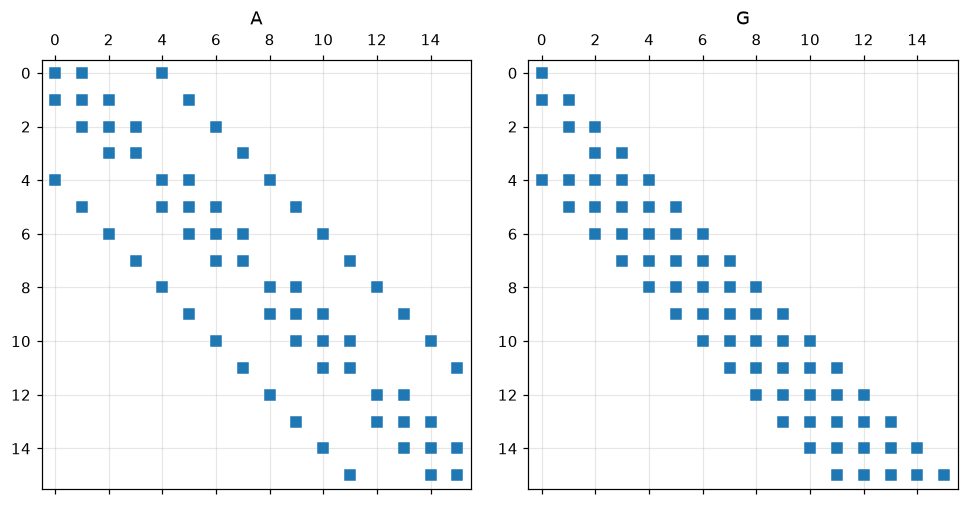

In [51]:
# Estructura de A y G (n = 4, 16x16)
A_4 = arma_A(4); G_4 = np.linalg.cholesky(A_4)
fig, axs = plt.subplots(1, 2, figsize=(9, 4.5))
axs[0].spy(A_4, markersize=6); axs[0].set_title("A")
axs[1].spy(np.where(np.abs(G_4) > tol, G_4, 0.0), markersize=6); axs[1].set_title("G")
fig.tight_layout()
plt.show()

In [52]:
# Comparación con lo esperado: semiancho = n; nz(A) = 5n^2 - 4n; nz(G inf) = n^2 (n+1) - n(n+1)/2
ok_e1 = all(r["m"] == r["n"] and r["mG"] == r["n"] for r in filas)
ok_e2 = all(r["nzA"] == 5*r["n"]**2 - 4*r["n"] for r in filas)
ok_e4 = all(r["nzG"] == r["n"]**2*(r["n"] + 1) - r["n"]*(r["n"] + 1)//2 for r in filas)
print("semiancho de A y G = n:", ok_e1)
print("nz(A) = 5n^2 - 4n:", ok_e2)
print("G llena su banda (nz = n^2(n+1) - n(n+1)/2):", ok_e4)
for r in filas:
    n = r["n"]
    print(f"  n = {n:2d}: nz(A) = {r['nzA']:5d} vs {5*n**2 - 4*n:5d}   nz(G) = {r['nzG']:6d} vs {n**2*(n + 1) - n*(n + 1)//2:6d}")
ok_e = bool(ok_e1 and ok_e2 and ok_e3 and ok_e4)

semiancho de A y G = n: True
nz(A) = 5n^2 - 4n: True
G llena su banda (nz = n^2(n+1) - n(n+1)/2): False
  n =  2: nz(A) =    12 vs    12   nz(G) =      9 vs      9
  n =  4: nz(A) =    64 vs    64   nz(G) =     67 vs     70
  n =  8: nz(A) =   288 vs   288   nz(G) =    519 vs    540
  n = 16: nz(A) =  1216 vs  1216   nz(G) =   4111 vs   4216
  n = 32: nz(A) =  4992 vs  4992   nz(G) =  32630 vs  33264


### Resumen del Problema 6

In [53]:
for nombre, ok in (("(a) esquema de cinco puntos", ok_a), ("(b) ensamble y bloques", ok_b),
                   ("(c) Cholesky n=2", ok_c), ("(d) solución con G", ok_d),
                   ("(e) banda y relleno", ok_e)):
    print(f"{nombre:30s} {'OK' if ok else 'REVISAR'}")

(a) esquema de cinco puntos    OK
(b) ensamble y bloques         OK
(c) Cholesky n=2               OK
(d) solución con G             OK
(e) banda y relleno            REVISAR


## Problema 7

### (d) Euler explícito contra CN

$\dfrac{d\boldsymbol{\varphi}}{dt}=-A\boldsymbol{\varphi}$ con $A=\operatorname{tridiag}(-1,2,-1)$ de $3\times3$ y $\boldsymbol{\varphi}^0=(0,1,0)^T$.
Se grafica el flujo del nodo central $\varphi_2$ contra el tiempo, con la solución exacta, Euler explícito y CN. Euler explícito necesita $\Delta t < 2/\rho(A)=2-\sqrt2\approx0.5858$. La figura se guarda en `latex/figuras/p07_solucion.pdf`.

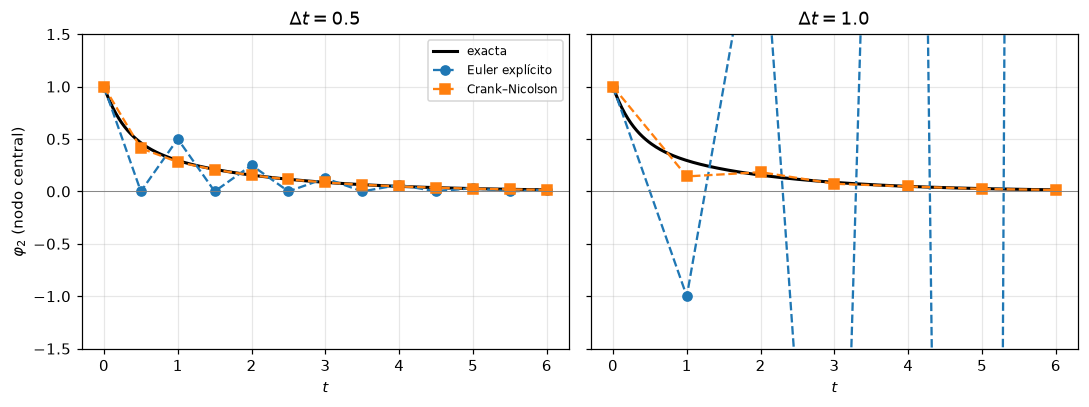

In [54]:
# Flujo φ en el nodo central contra el tiempo: exacta, Euler explícito y CN.
# >>> CAMBIA AQUÍ: dts = los pasos Δt (uno por gráfica), T7 = tiempo final, phi0_7 = condición inicial.
# (El límite de Euler explícito es Δt < 2/ρ(A) = 2 - √2 ≈ 0.5858.)
dts = [0.5, 1.0]
T7 = 6.0
phi0_7 = np.array([0.0, 1.0, 0.0])

A7 = np.array([[2., -1., 0.], [-1., 2., -1.], [0., -1., 2.]])    # tridiag(-1, 2, -1)
I7 = np.eye(3)

# Solución exacta de φ' = -A φ (por valores propios): φ(t) = V exp(-Λt) Vᵀ φ0
w7, V7 = np.linalg.eigh(A7)
t_fino = np.linspace(0, T7, 300)
phi_exacta = np.array([V7 @ (np.exp(-w7 * t) * (V7.T @ phi0_7)) for t in t_fino])

fig, axs = plt.subplots(1, len(dts), figsize=(10, 3.8), sharey=True)
for ax, dt7 in zip(axs, dts):
    n_pasos = int(round(T7 / dt7))
    phi_E = [phi0_7]; phi_C = [phi0_7]
    for _ in range(n_pasos):
        phi_E.append((I7 - dt7 * A7) @ phi_E[-1])                                  # Euler explícito
        phi_C.append(np.linalg.solve(I7 + dt7 * A7 / 2, (I7 - dt7 * A7 / 2) @ phi_C[-1]))  # CN
    t_n = dt7 * np.arange(n_pasos + 1)
    ax.plot(t_fino, phi_exacta[:, 1], "k-", lw=2, label="exacta")
    ax.plot(t_n, [p[1] for p in phi_E], "o--", label="Euler explícito")
    ax.plot(t_n, [p[1] for p in phi_C], "s--", label="Crank–Nicolson")
    ax.axhline(0, color="gray", lw=0.6)
    ax.set_ylim(-1.5, 1.5)          # Euler explícito se sale del recuadro cuando es inestable
    ax.set_title(rf"$\Delta t = {dt7}$")
    ax.set_xlabel("$t$")
    ax.grid(alpha=0.3)
axs[0].set_ylabel(r"$\varphi_2$ (nodo central)")
axs[0].legend(fontsize=8, loc="upper right")
fig.tight_layout()
fig.savefig(FIG / "p07_solucion.pdf", bbox_inches="tight")
plt.show()


## Problema 8

### (d) CN en 1D y orden 2 en $\Delta t$

Se avanza con Crank–Nicolson, $B^+\boldsymbol{\varphi}^{k+1}=B^-\boldsymbol{\varphi}^k$ con $B^\pm=I\pm\frac{v\Delta t}{2}A_1$, factorizando $B^+$ con Cholesky **una sola vez** antes del ciclo. Se compara contra la solución exacta del sistema semidiscreto en $T=0.1$ y se estima el orden. Es el mismo código de `python/problemas/p8.py`.

In [55]:
import numpy as np
from scipy.linalg import cho_factor, cho_solve

D, v = 1.0, 1.0
h = 1/20
n = 19
x = h*np.arange(1, n+1)
T = 0.1

A1 = (D/h**2)*(2*np.eye(n) - np.eye(n, k=1) - np.eye(n, k=-1))
I = np.eye(n)

mu = 2/h**2*(1 - np.cos(np.pi*h))
exacta = np.exp(-v*mu*T)*np.sin(np.pi*x)

errores = []
for dt in [0.02, 0.01, 0.005, 0.0025]:
    K = round(T/dt)
    Bmas = I + v*dt/2*A1
    Bmenos = I - v*dt/2*A1
    G = cho_factor(Bmas)
    phi = np.sin(np.pi*x)
    for k in range(K):
        phi = cho_solve(G, Bmenos @ phi)
    eps = np.max(np.abs(exacta - phi))
    errores.append(eps)
    print(f"dt = {dt:<7} K = {K:3d}  error = {eps:.6e}")

for m in range(3):
    R = errores[m]/errores[m+1]
    print(f"R = {R:.6f}   OCG = {np.log(R)/np.log(2):.6f}")

dt = 0.02    K =   5  error = 1.194511e-03
dt = 0.01    K =  10  error = 2.976782e-04
dt = 0.005   K =  20  error = 7.436052e-05
dt = 0.0025  K =  40  error = 1.858645e-05
R = 4.012759   OCG = 2.004595
R = 4.003176   OCG = 2.001145
R = 4.000793   OCG = 2.000286
